In [32]:
import duckdb
import polars as pl

In [45]:
# خواندن فایل 
CSV_PATH = 'digikala-comments.csv'
NULL_TOKENS = ['null', 'NULL', 'Null', 'NaN', 'nan', 'NAN', 'None', 'NA', 'N/A', '']

df1 = pl.read_csv(
    CSV_PATH,
    null_values=NULL_TOKENS,
)
df1.null_count()

id,title,body,created_at,rate,recommendation_status,is_buyer,product_id,advantages,disadvantages,likes,dislikes,seller_title,seller_code,true_to_size_rate
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,2865062,637,0,0,894426,0,0,5448084,5744017,0,0,302181,302181,6065516


In [46]:
# حذف ستون های seller_code و true_to_size_rate
df1 = df1.drop(['seller_code', 'true_to_size_rate']).with_columns(pl.col('seller_title').fill_null('نامشخص'))

# اضافه کردن دوتا ستون has_advantages و has_disadvantages
df1 = df1.with_columns(
    pl.col('advantages').is_not_null().alias('has_advantages'),
    pl.col('disadvantages').is_not_null().alias('has_disadvantages'),
).with_columns(
    pl.col('advantages').fill_null(''),
    pl.col('disadvantages').fill_null(''),
)
df1 = df1.filter(pl.col('recommendation_status').is_not_null())

In [47]:
df1.null_count()

id,title,body,created_at,rate,recommendation_status,is_buyer,product_id,advantages,disadvantages,likes,dislikes,seller_title,has_advantages,has_disadvantages
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,2434448,501,0,0,0,0,0,0,0,0,0,0,0,0


In [52]:
df1 = df1.filter(pl.col('body').is_not_null())


df1.null_count()

id,title,body,created_at,rate,recommendation_status,is_buyer,product_id,advantages,disadvantages,likes,dislikes,seller_title,has_advantages,has_disadvantages
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,2434409,0,0,0,0,0,0,0,0,0,0,0,0,0


In [53]:
df1 = df1.filter(pl.col('body').is_not_null())


df2 = df1.with_columns(
    pl.col('body').str.len_chars().alias('body_len_char'),
    pl.col('body').str.split(' ').list.len().alias('body_len_word'),
)
# print(df2.select('body', 'body_len_char', 'body_len_word').head())
# print(df2.select(pl.col('body_len_char', 'body_len_word').describe()))


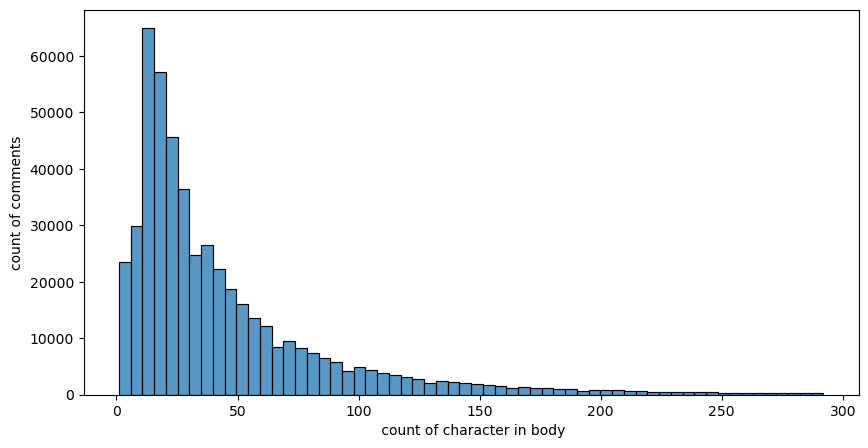

In [64]:
import seaborn as sns
import matplotlib.pyplot as plt

# نمونه‌گیری برای سرعت (اختیاری)
s = df2.select('body_len_char').drop_nulls().sample(500_000, seed=42).to_series().to_numpy()

p99 = int(pl.Series(s).quantile(0.99))

plt.figure(figsize=(10, 5))
sns.histplot(s[s <= p99], bins=60)
plt.xlabel(' count of character in body')
plt.ylabel('count of comments')
plt.show()

In [65]:
KEEP = (
    r"\x{0600}-\x{06FF}\x{FB50}-\x{FDFF}\x{FE70}-\x{FEFF}"
    r"a-zA-Z0-9\s\x{200C}.,،؛:!?()\[\]«»\-…"
    r"\x{1F300}-\x{1FAFF}\x{2600}-\x{27BF}\x{2300}-\x{23FF}\x{2B00}-\x{2BFF}"
    r"\x{1F000}-\x{1F2FF}\x{00A9}\x{00AE}\x{203C}\x{2049}\x{2122}\x{2139}\x{2194}-\x{21AA}"
    r"\x{200D}\x{FE0F}"
)
INVISIBLE = r"[\x{200B}\x{200E}\x{200F}\x{202A}-\x{202E}\x{2066}-\x{2069}\x{FEFF}\x{00AD}\x{1F3FB}-\x{1F3FF}]"

def rx(e, pat, rep):
    return f"regexp_replace({e}, '{pat}', '{rep}', 'g')"

def build_clean_expr(col="body"):
    e = col
    e = rx(e, r"<[^>]+>|(https?://|www\.)\S+", " ")
    e = rx(e, "[^" + KEEP + "]", " ")
    e = rx(e, INVISIBLE, "")
    e = f"translate({e}, '٠١٢٣٤٥٦٧٨٩۰۱۲۳۴۵۶۷۸۹ يك', '01234567890123456789 یک')"
    e = rx(e, r"[!]{3,}", "!!")
    e = rx(e, r"[?]{3,}", "??")
    e = rx(e, r"[.]{4,}", "...")
    e = rx(e, r"\s+", " ")
    return f"trim({e})"

# 1) حذف body خالی
n0 = df1.height
df1 = df1.filter(pl.col('body').is_not_null())
print('قبل:', n0, '| بعد:', df1.height, '| حذف‌شده:', n0 - df1.height)

# 2) ساخت body_clean (اگر از قبل هست، حذف و دوباره ساخته می‌شود)
df1 = df1.drop('body_clean', strict=False)
duckdb.register('df1_tbl', df1)
df1 = duckdb.sql(f"""
    SELECT *, {build_clean_expr('body')} AS body_clean
    FROM df1_tbl
""").pl()



قبل: 5261362 | بعد: 5261362 | حذف‌شده: 0


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

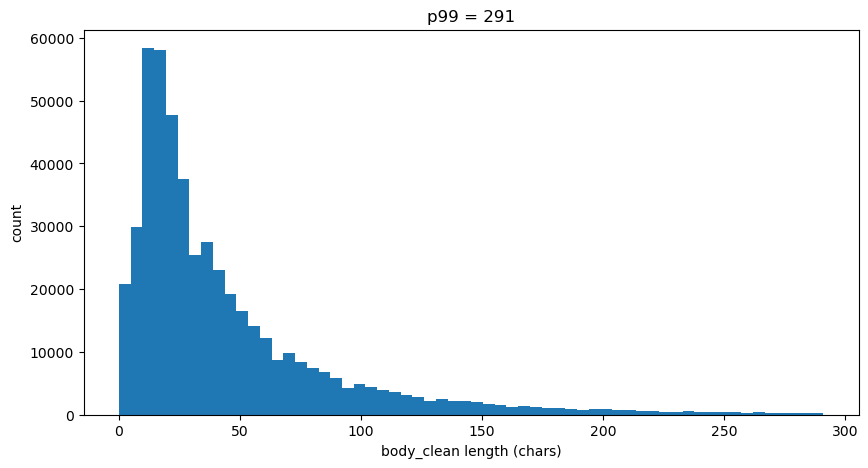

In [66]:
import matplotlib.pyplot as plt

lens = df1.select(pl.col('body_clean').str.len_chars().alias('n')).to_series()
s = lens.sample(500_000, seed=42).to_numpy()
p99 = int(lens.quantile(0.99))

plt.figure(figsize=(10, 5))
plt.hist(s[s <= p99], bins=60)
plt.xlabel('body_clean length (chars)')
plt.ylabel('count')
plt.title(f'p99 = {p99}')
plt.show()

In [61]:
df1.write_csv('df1_clean.csv')

In [63]:
df1.write_parquet('df1_clean.parquet')